In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [27]:
df = pd.read_csv(r'C:\Users\User\OneDrive\Desktop\I am python\15stocks_price.csv') # Stock Price Data
df['date_gsheets'] = pd.to_datetime(df['Date'])
df.set_index('date_gsheets', inplace=True)

returns_df = df.drop(columns=['Date']).pct_change(1)
returns_df.dropna(inplace=True)

In [28]:
#Round to 2 decimal places
corr_matrix = returns_df.corr().round(2)

corr_matrix

,AAPL,AMZN,GOOGL,HD,JNJ,JPM,MA,META,MSFT,NVDA,PG,TSLA,UNH,V,WMT,Market
AAPL,1.00,0.56,0.58,0.44,0.15,0.35,0.51,0.49,0.63,0.52,0.25,0.50,0.14,0.49,0.29,0.76
AMZN,0.56,1.00,0.62,0.40,0.01,0.34,0.43,0.60,0.65,0.56,0.09,0.45,0.09,0.40,0.24,0.72
GOOGL,0.58,0.62,1.00,0.32,0.07,0.32,0.42,0.56,0.64,0.53,0.11,0.42,0.12,0.39,0.20,0.69
HD,0.44,0.40,0.32,1.00,0.26,0.36,0.43,0.34,0.40,0.31,0.34,0.27,0.19,0.41,0.35,0.60
JNJ,0.15,0.01,0.07,0.26,1.00,0.21,0.23,0.02,0.08,-0.10,0.45,-0.01,0.25,0.25,0.23,0.22
JPM,0.35,0.34,0.32,0.36,0.21,1.00,0.48,0.29,0.31,0.32,0.19,0.31,0.18,0.48,0.23,0.62
MA,0.51,0.43,0.42,0.43,0.23,0.48,1.00,0.40,0.49,0.38,0.33,0.31,0.21,0.88,0.27,0.68
META,0.49,0.60,0.56,0.34,0.02,0.29,0.40,1.00,0.59,0.50,0.10,0.35,0.03,0.36,0.19,0.63
MSFT,0.63,0.65,0.64,0.40,0.08,0.31,0.49,0.59,1.00,0.63,0.20,0.42,0.14,0.45,0.25,0.76
NVDA,0.52,0.56,0.53,0.31,-0.10,0.32,0.38,0.50,0.63,1.00,0.01,0.47,0.06,0.36,0.12,0.70


In [29]:
corr_matrix[['AMZN', 'JNJ']]

,AMZN,JNJ
AAPL,0.56,0.15
AMZN,1.00,0.01
GOOGL,0.62,0.07
HD,0.40,0.26
JNJ,0.01,1.00
JPM,0.34,0.21
MA,0.43,0.23
META,0.60,0.02
MSFT,0.65,0.08
NVDA,0.56,-0.10


In [30]:
#create a lower trangle mask and appply it (setting upper triangle to NaN or blank))
mask = np.tril(np.ones_like(corr_matrix, dtype=bool))
lower_corr_matrix = corr_matrix.where(mask)

#Display the result
lower_corr_matrix

,AAPL,AMZN,GOOGL,HD,JNJ,JPM,MA,META,MSFT,NVDA,PG,TSLA,UNH,V,WMT,Market
AAPL,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AMZN,0.56,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GOOGL,0.58,0.62,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HD,0.44,0.40,0.32,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
JNJ,0.15,0.01,0.07,0.26,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
JPM,0.35,0.34,0.32,0.36,0.21,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MA,0.51,0.43,0.42,0.43,0.23,0.48,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
META,0.49,0.60,0.56,0.34,0.02,0.29,0.40,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MSFT,0.63,0.65,0.64,0.40,0.08,0.31,0.49,0.59,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NVDA,0.52,0.56,0.53,0.31,-0.10,0.32,0.38,0.50,0.63,1.00,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
corr_matrix[['AAPL', 'NVDA','TSLA','MSFT','GOOGL']]

,AAPL,NVDA,TSLA,MSFT,GOOGL
AAPL,1.00,0.52,0.50,0.63,0.58
AMZN,0.56,0.56,0.45,0.65,0.62
GOOGL,0.58,0.53,0.42,0.64,1.00
HD,0.44,0.31,0.27,0.40,0.32
JNJ,0.15,-0.10,-0.01,0.08,0.07
JPM,0.35,0.32,0.31,0.31,0.32
MA,0.51,0.38,0.31,0.49,0.42
META,0.49,0.50,0.35,0.59,0.56
MSFT,0.63,0.63,0.42,1.00,0.64
NVDA,0.52,1.00,0.47,0.63,0.53


In [32]:
corr_matrix[['NVDA', 'TSLA','AMZN','MSFT','GOOGL']]

,NVDA,TSLA,AMZN,MSFT,GOOGL
AAPL,0.52,0.50,0.56,0.63,0.58
AMZN,0.56,0.45,1.00,0.65,0.62
GOOGL,0.53,0.42,0.62,0.64,1.00
HD,0.31,0.27,0.40,0.40,0.32
JNJ,-0.10,-0.01,0.01,0.08,0.07
JPM,0.32,0.31,0.34,0.31,0.32
MA,0.38,0.31,0.43,0.49,0.42
META,0.50,0.35,0.60,0.59,0.56
MSFT,0.63,0.42,0.65,1.00,0.64
NVDA,1.00,0.47,0.56,0.63,0.53


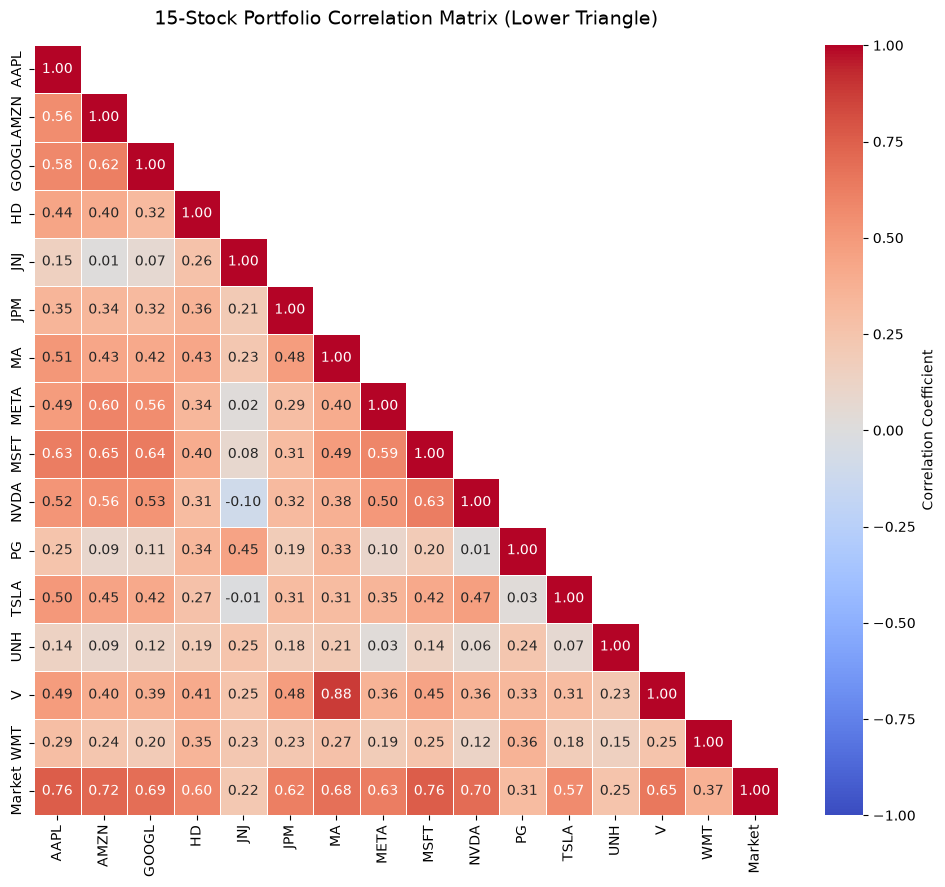

In [33]:
plt.figure(figsize=(12, 10))
# Generate the heatmap with annotations and a diverging colormap
sns.heatmap(
    lower_corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Correlation Coefficient"},
)
plt.title(
    "15-Stock Portfolio Correlation Matrix (Lower Triangle)",
    fontsize=14,
    pad=15,
)
plt.show()

In [34]:
from scipy.optimize import minimize

# 1. Clean data and compute covariance matrix as a NumPy array
clean_returns_df = returns_df.drop(columns=["Market"], errors="ignore")
cov_matrix = clean_returns_df.cov().values
num_assets = len(clean_returns_df.columns)


# 2. Define portfolio variance using clean NumPy matrix multiplication (@)
def portfolio_variance(weights, cov):
  return weights @ cov @ weights


# 3. Initial weights (equal distribution)
initial_weights = np.array([1.0 / num_assets] * num_assets)

# 4. Bounds (0 to 1, no short-selling) and Constraint (weights sum to 1)
bounds = tuple((0.0, 1.0) for _ in range(num_assets))
constraints = {"type": "eq", "fun": lambda x: np.sum(x) - 1.0}

# 5. Run optimization
opt_result = minimize(
    portfolio_variance,
    initial_weights,
    args=(cov_matrix,),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"maxiter": 1000, "ftol": 1e-9},
)

# 6. Print full results to check status
print(opt_result)
print("\n" + "=" * 40 + "\n")

# 7. Display true optimized weights if successful
if opt_result.success:
  optimal_weights = pd.Series(
      opt_result.x, index=clean_returns_df.columns
  ).round(4)
  print("True Minimum Variance Portfolio (MVP) Optimal Weights:")
  print(optimal_weights)
  print("Sum of weights:", np.sum(opt_result.x))
else:
  print("Optimization failed:", opt_result.message)

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 6.258070579179679e-05
           x: [ 8.132e-19  9.353e-03 ...  1.660e-02  1.706e-01]
         nit: 47
         jac: [ 1.334e-04  1.260e-04 ...  1.259e-04  1.313e-04]
        nfev: 752
        njev: 47
 multipliers: [ 1.252e-04]


True Minimum Variance Portfolio (MVP) Optimal Weights:
AAPL     0.0000
AMZN     0.0094
GOOGL    0.0229
HD       0.0173
JNJ      0.3195
JPM      0.0812
MA       0.0205
META     0.0000
MSFT     0.0469
NVDA     0.0116
PG       0.2428
TSLA     0.0000
UNH      0.0407
V        0.0166
WMT      0.1706
dtype: float64
Sum of weights: 0.9999999999999999
